# MCMC analysis for Kerr spacetime metric as modeled S2 star orbiting around SgrA*

## Kerr metric $$ds^2 = -\left(1 - \frac{2Mr}{\Sigma}\right) dt^2 - \frac{4Mar\sin^2\theta}{\Sigma} dt\,d\phi 
    + \frac{\Sigma}{\Delta} dr^2 + \Sigma\, d\theta^2 + \left(r^2 + a^2 + \frac{2Ma^2 r \sin^2\theta}{\Sigma}\right) \sin^2\theta\, d\phi^2
$$

### where $ 
  \Sigma = r^2 + a^2 \cos^2\theta, \\
    \Delta = r^2 - 2Mr + a^2.
   $

## Schwarzschild solution of Einstein equation $$ f(r) = 1-\frac{2 G M}{c^2 r}$$


## $G_{\mu\nu} \sim a T_{\mu\nu}$

In [ ]:
import numpy as np
import emcee
import corner
import matplotlib.pyplot as plt
import math

In [6]:
import numpy as np 
from scipy import integrate
import math
from scipy.optimize import root

def _R_potential(E, Lz, r, a, M):
    Delta = r**2 - 2*M*r + a**2
    term1 = E * (r**2 + a**2) - a * Lz
    term2 = r**2 + (Lz - a * E)**2
    return term1**2 - Delta * term2

def _root_system(vars, Lambda, e, a, M):
    E, Lz = vars
    r_peri = Lambda * M / (1 + e)
    r_apo = Lambda * M / (1 - e)
    return [_R_potential(E, Lz, r_peri, a, M), _R_potential(E, Lz, r_apo, a, M)]

def epsilon(Lambda, e, a, M):
    """
    Kerr specific energy for given semi-latus rectum Lambda, eccentricity e, spin a, mass M.
    """
    # Initial guess from Schwarzschild approximation
    E0 = np.sqrt((1 - 2*M / (Lambda*M)) / (1 - 3*M / (Lambda*M)))
    Lz0 = np.sqrt(Lambda * M**2 / (1 - 3*M / (Lambda*M)))

    sol = root(_root_system, [E0, Lz0], args=(Lambda, e, a, M), method='hybr')
    if sol.success:
        E, _ = sol.x
        return E
    else:
        raise RuntimeError("Root finding failed for energy: " + sol.message)

def l(Lambda, e, a, M):
    """
    Kerr specific angular momentum for given semi-latus rectum Lambda, eccentricity e, spin a, mass M.
    """
    # Initial guess from Schwarzschild approximation
    E0 = np.sqrt((1 - 2*M / (Lambda*M)) / (1 - 3*M / (Lambda*M)))
    Lz0 = np.sqrt(Lambda * M**2 / (1 - 3*M / (Lambda*M)))

    sol = root(_root_system, [E0, Lz0], args=(Lambda, e, a, M), method='hybr')
    if sol.success:
        _, Lz = sol.x
        return Lz
    else:
        raise RuntimeError("Root finding failed for angular momentum: " + sol.message)

# def epsilon(Lambda, e, s, M):   
#     output = (
#         np.sqrt(((Lambda - 2*M)**2 - 4*M**2 * e**2) / (Lambda * (Lambda - M*(3 + e**2))))
#         + s * (
#             ((e**2 - 1)**2 * M * np.sqrt(M * Lambda * (Lambda**2 - 4*M*Lambda - 4*M**2*(e**2 - 1))))
#             / (Lambda**2 * (Lambda - M*(3 + e**2))**2)
#         )
#     )              
#     return output

    
# def l(Lambda, e, s, M):   
#     output = np.sqrt(
#         (M * Lambda**2) / (Lambda - M * (3 + e**2))
#         - s * (
#             (2*Lambda - 3*M*(3 + e**2)) * np.sqrt(M * Lambda * (Lambda**2 - 4*M*Lambda - 4*M**2*(e**2 - 1)))
#         ) / (Lambda - M * (3 + e**2))**2
#     )               
#     return output

    
def phi(r, l, epsilon, s, M):
    output = 1 / np.sqrt(
        (
            r * (l**2 * (2*M - r)
                 + 2*l*s*epsilon*(-3*M + r)
                 + r**2 * (2*M + r * (-1 + epsilon**2))
            )
        ) / (l + s*epsilon)**2
    )
    return output


def result(Lambda, e, s, M):
    lower_limit = Lambda / (1 - e)  # pericenter
    upper_limit = 204               # some large radius (apocenter or numerical cutoff)

    epsilon_value = epsilon(Lambda, e, s, M)  # energy
    l_value = l(Lambda, e, s, M)              # angular momentum

    output = integrate.quad(phi, lower_limit, upper_limit, args=(l_value, epsilon_value, s, M)) 
    return output


In [7]:
import numpy as np
def nuX(Lambda,e,s,M,Omega,gamma,a):
    lower_limit=Lambda/(1-e)
    upper_limit=204
    epsilon_value=epsilon(Lambda,e,s,M)
    l_value=l(Lambda,e,s,M)
    result=integrate.quad(phi, lower_limit, upper_limit, args=(l_value, epsilon_value, s, M))
    output = 204*math.cos(result[0])*(math.sin(Omega)*math.cos(gamma)+math.cos(Omega)*math.sin(gamma)*math.cos(a))+204*math.sin(result[0])*(-math.sin(Omega)*math.sin(gamma)+math.cos(Omega)*math.cos(gamma)*math.cos(a))
    return output

def nuY(Lambda,e,s,M,Omega,gamma,a):
    lower_limit=Lambda/(1-e)
    upper_limit=204
    epsilon_value=epsilon(Lambda,e,s,M)
    l_value=l(Lambda,e,s,M)
    result=integrate.quad(phi, lower_limit, upper_limit, args=(l_value, epsilon_value, s, M))
    output = 204*math.cos(result[0])*(math.cos(Omega)*math.cos(gamma)-math.sin(Omega)*math.sin(gamma)*math.cos(a))+204*math.sin(result[0])*(-math.cos(Omega)*math.sin(gamma)-math.sin(Omega)*math.cos(gamma)*math.cos(a))
    return output

In [18]:
import numpy as np
import emcee
import corner
import matplotlib.pyplot as plt

# Define the S2 star observation data
nX = 20.1       # X coordinate of the S2 star
dX11 = 4.8      # Error in X
nY = -225       # Y coordinate of the S2 star
dY11 = 5        # Error in Y

# Define the parameter ranges
s_range=(0.0,0.9)
Lambda_range = (1.9, 3.0)
e_range = (0.71, 0.91)
M_range = (3.9, 4.2)
Omega_range = (3.2, 3.8)
gamma_range = (1.18, 1.187)
a_range = (2.327, 2.345)
rd_range = (8.15, 8.35)
Vr_range = (47, 133)
vx_range = (-0.09, -0.05)
vy_range = (0.215, 0.229)
x_range = (0.985, 1.235)
y_range = (-0.9, -0.83)

# Define the log prior function
def ln_prior(parameters):
    s, Lambda, e, M, Omega, gamma, a, rd, Vr, vx, vy, x, y = parameters

    # Range check
    if not (s_range[0] <= s <= s_range[1] and
        Lambda_range[0] <= Lambda <= Lambda_range[1] and
        e_range[0] <= e <= e_range[1] and
        M_range[0] <= M <= M_range[1] and
        Omega_range[0] <= Omega <= Omega_range[1] and
        gamma_range[0] <= gamma <= gamma_range[1] and
        a_range[0] <= a <= a_range[1] and
        rd_range[0] <= rd <= rd_range[1] and
        Vr_range[0] <= Vr <= Vr_range[1] and
        vx_range[0] <= vx <= vx_range[1] and
        vy_range[0] <= vy <= vy_range[1] and
        x_range[0] <= x <= x_range[1] and
        y_range[0] <= y <= y_range[1]
    ):
        return -np.inf

    # Gaussian priors
    ln_priors = -0.5 * ((s - 0.5) / 0.1)**2
    ln_priors += -0.5 * ((Lambda - 0.8) / 0.1) ** 2
    ln_priors += -0.5 * ((e - 0.82) / 0.025) ** 2
    ln_priors += -0.5 * ((M - 4.05) / 0.05) ** 2
    ln_priors += -0.5 * ((Omega - 3.9625) / 0.0445) ** 2
    ln_priors += -0.5 * ((gamma - 1.2045) / 0.0006) ** 2
    ln_priors += -0.5 * ((a - 2.33556) / 0.00162) ** 2
    ln_priors += -0.5 * ((rd - 8.25) / 0.0162) ** 2
    ln_priors += -0.5 * ((Vr - 90) / 15) ** 2
    ln_priors += -0.5 * ((vx + 0.07) / 0.005) ** 2
    ln_priors += -0.5 * ((vy - 0.2235) / 0.0015) ** 2
    ln_priors += -0.5 * ((x - 1.105) / 0.05) ** 2
    ln_priors += -0.5 * ((y + 0.865) / 0.0075) ** 2

    return ln_priors

# Placeholder functions (replace these with actual astrophysical models)
def nuX(Lambda, e, t, M, Omega, gamma, a):
    # Example model (linear placeholder)
    return Lambda * 0.1 + e * 10 + M

def nuY(Lambda, e, t, M, Omega, gamma, a):
    # Example model (linear placeholder)
    return -Lambda * 3 + Omega * 4 + gamma * 1000

# Log-likelihood function
def ln_likelihood(parameters):
    s, Lambda, e, M, Omega, gamma, a, rd, Vr, vx, vy, x, y = parameters

    # Calculate model predictions
    nX_model = nuX(Lambda, e, s, M, Omega, gamma, a)
    nY_model = nuY(Lambda, e, s, M, Omega, gamma, a)

    # Likelihood assuming Gaussian error
    ln_likelihood_X = -0.5 * ((nX - nX_model) / dX11) ** 2
    ln_likelihood_Y = -0.5 * ((nY - nY_model) / dY11) ** 2

    return ln_likelihood_X + ln_likelihood_Y

# Posterior function
def ln_posterior(parameters):
    lp = ln_prior(parameters)
    if not np.isfinite(lp):
        return -np.inf
    return lp + ln_likelihood(parameters)  # no need for np.exp(-4) here

# MCMC configuration
nwalkers = 1000
ndim = 13

# Initial guess: random uniform within bounds
initial_guess = np.random.uniform(
    low=[
        s_range[0],Lambda_range[0], e_range[0], M_range[0], Omega_range[0], gamma_range[0], a_range[0],
        rd_range[0], Vr_range[0], vx_range[0], vy_range[0], x_range[0], y_range[0]
    ],
    high=[
        s_range[1],Lambda_range[1], e_range[1], M_range[1], Omega_range[1], gamma_range[1], a_range[1],
        rd_range[1], Vr_range[1], vx_range[1], vy_range[1], x_range[1], y_range[1]
    ],
    size=(nwalkers, ndim)
)


100%|██████████| 1000/1000 [00:09<00:00, 110.69it/s]


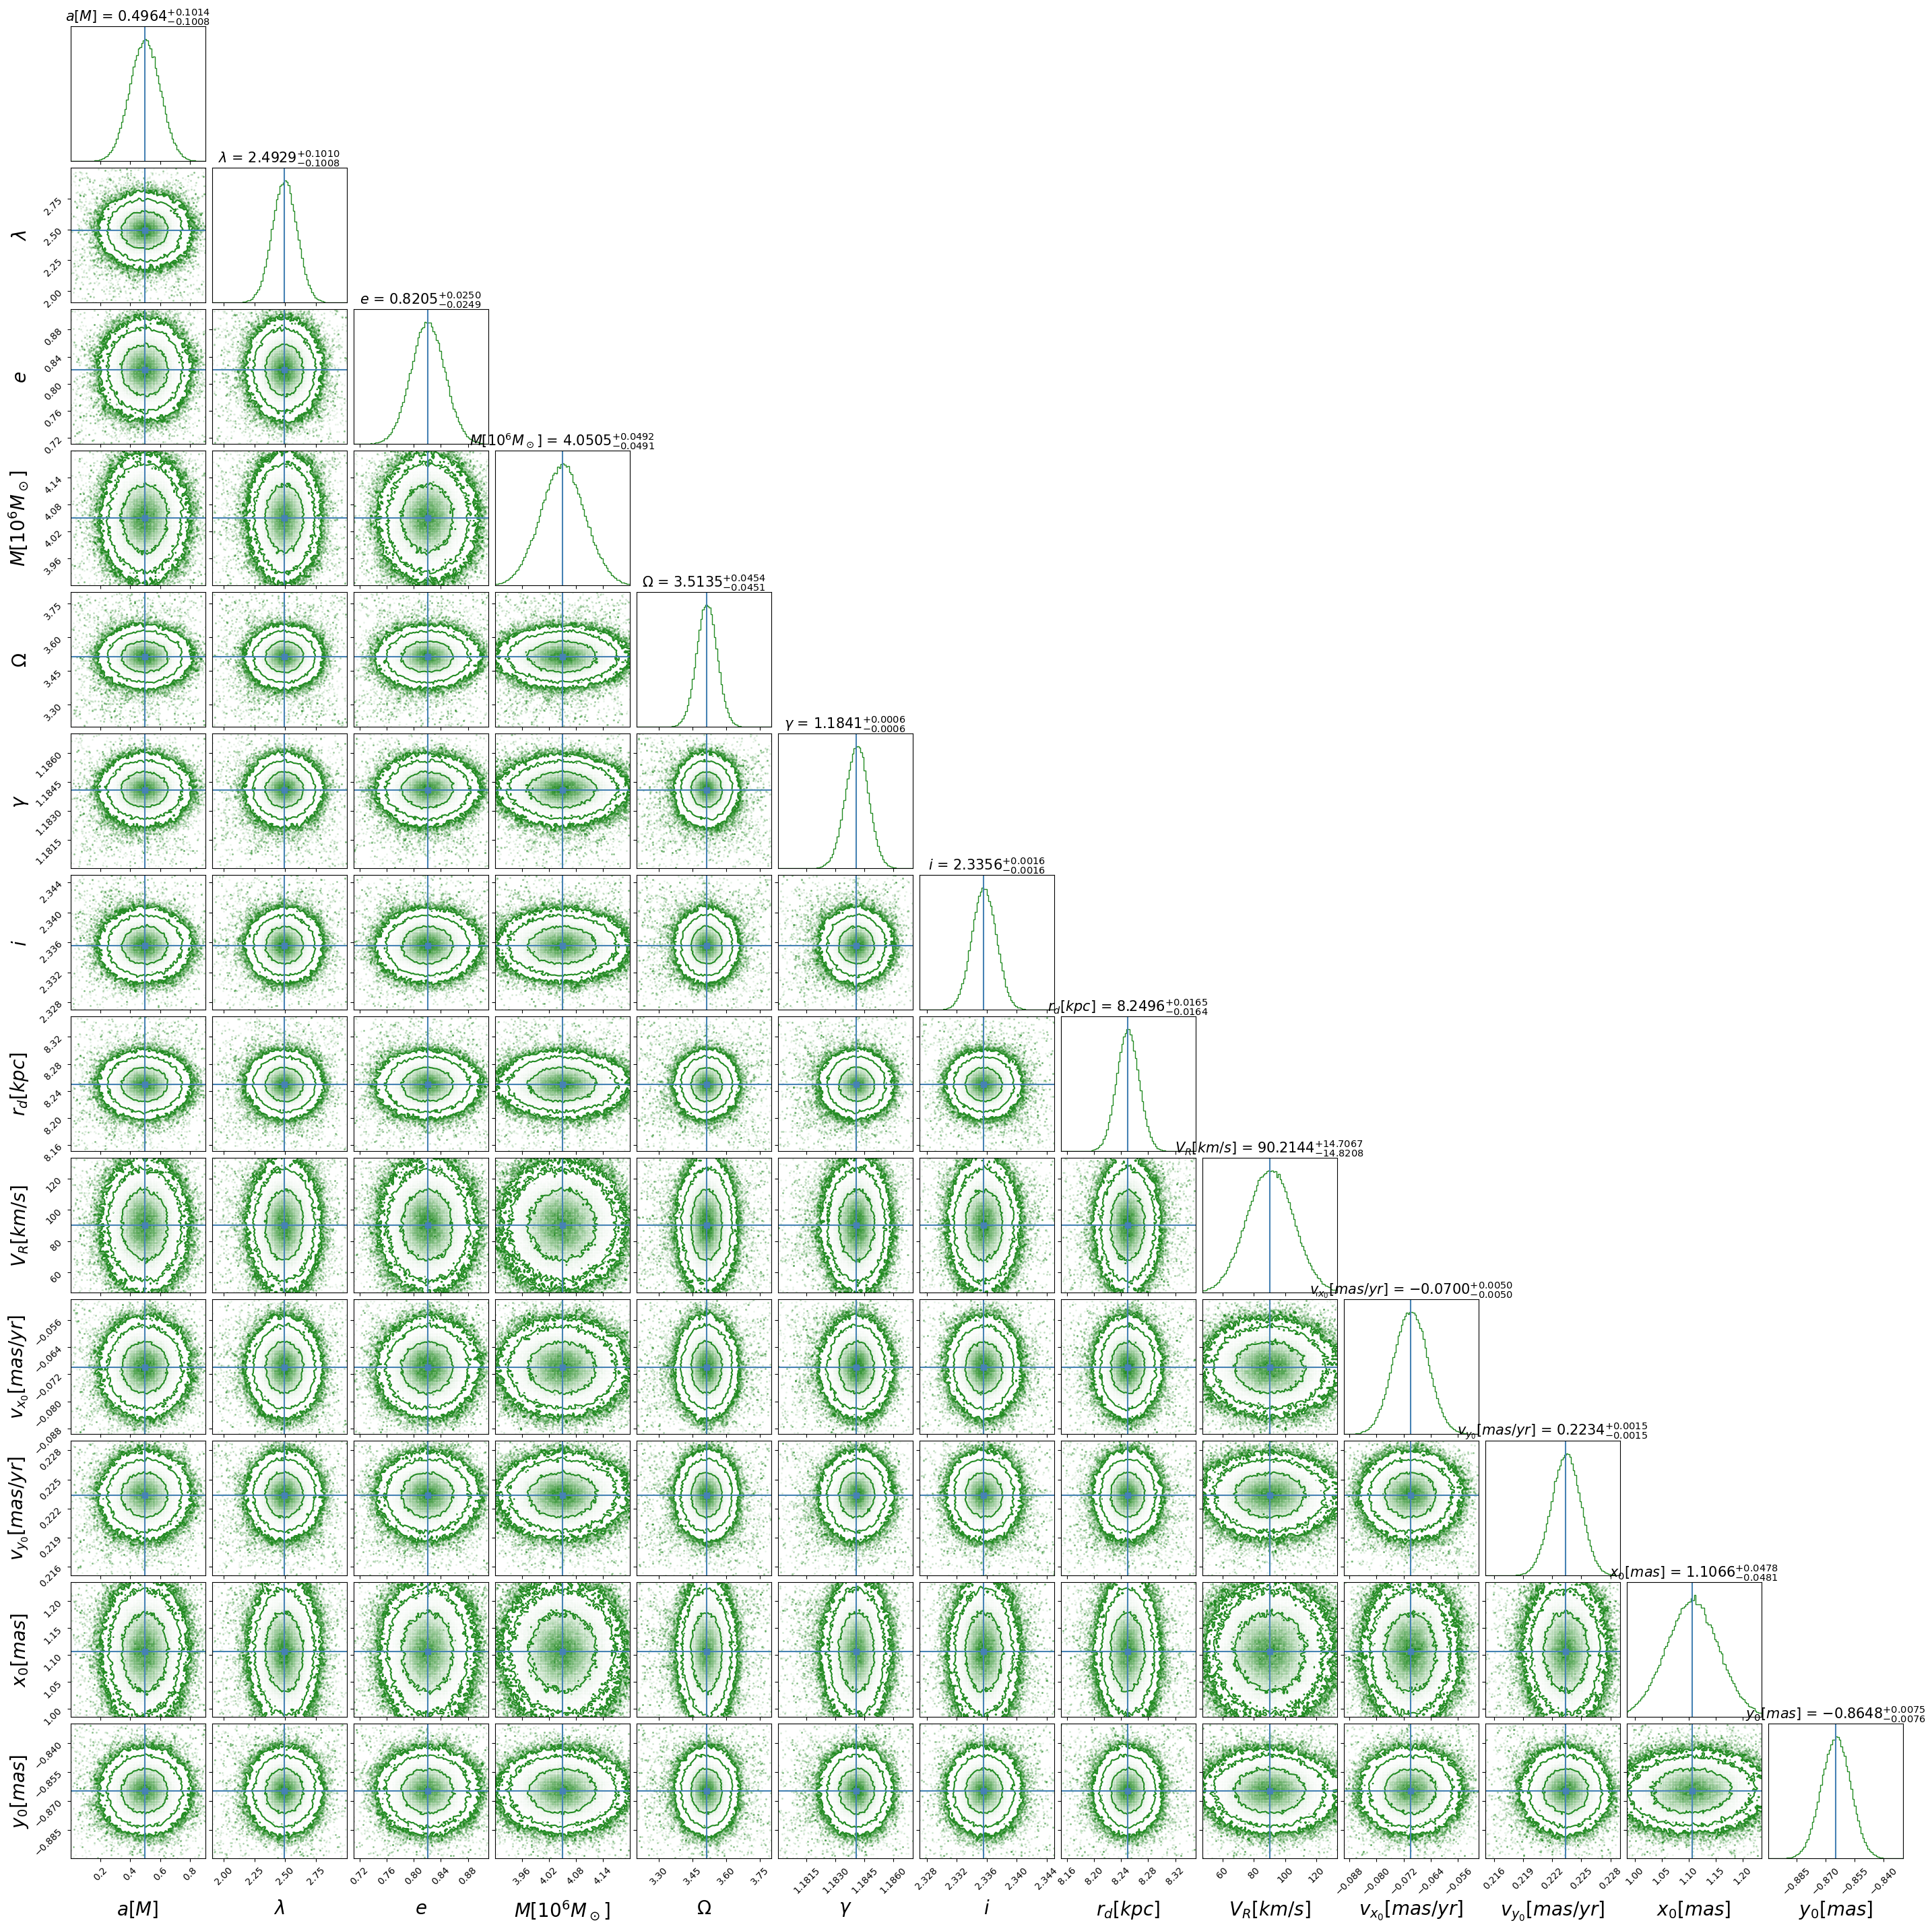

In [19]:
# Set up the emcee sampler
sampler = emcee.EnsembleSampler(nwalkers, ndim, ln_posterior)

# Run the sampler
n_steps = 1000  # Number of steps
sampler.run_mcmc(initial_guess, n_steps, progress=True)

# Extract the samples
samples = sampler.get_chain(flat=True)
    
levels = [0.68,0.95,0.99]

# Create a corner plot to visualize the pairwise relationships
corner_labels = [r'$a[M]$',r'$\lambda$', r'$e$', r'$M [10^6M_\odot]$', r'$\Omega$',r'$\gamma$',r'$i$',r'$r_d[kpc]$',r'$V_R[km/s]$',r'$v_{x_0}[mas/yr]$',r'$v_{y_0}[mas/yr]$',r'$x_0[mas]$',r'$y_0[mas]$']
corner.corner(samples,color="forestgreen",bins = 80,truths=np.mean(samples, axis=0), labels=corner_labels,levels=levels,  show_titles=True, title_fmt=(".4f"),label_kwargs={"fontsize": 20},title_kwargs={"fontsize": 15})
plt.savefig("KERRS2starMCMC.pdf", format='pdf')
plt.show()
plt.close()

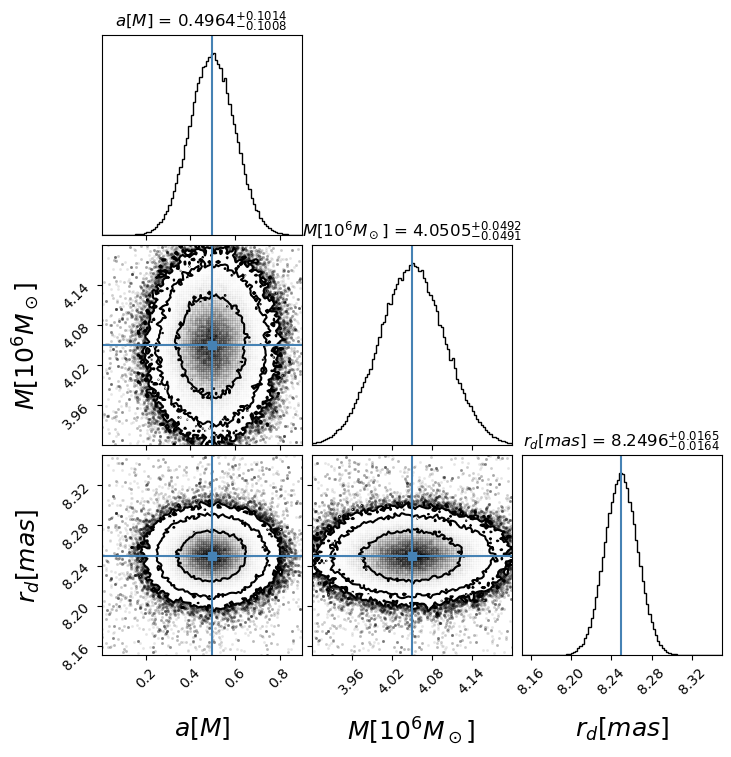

In [21]:
import numpy as np
import corner
import matplotlib.pyplot as plt

# Extract the samples
samples = sampler.get_chain(flat=True)

# Select only M (index 2) and r_d (index 6)
selected_samples = samples[:, [0,3,7]]

# Labels for the selected parameters
corner_labels = [r'$a[M]$',r'$M [10^6M_\odot]$', r'$r_d[mas]$']

# Corner plot for M and r_d
corner.corner(
    selected_samples,
    bins=90,
    truths=np.mean(selected_samples, axis=0),
    labels=corner_labels,
    levels=[0.68, 0.95, 0.99],
    show_titles=True,
    title_fmt=".4f",
    label_kwargs={"fontsize": 18},
    title_kwargs={"fontsize": 12}
)

plt.savefig("KerrS2starMCMC2.pdf", format='pdf')
plt.show()
plt.close()

## Quantum Mechanics. Problem Solution

Electrom mass $m_e = 9.1~10^{-31} kg$ or in electron Volts : $M_e \simeq 0.511 MeV$